In [94]:
import pandas as pd

In [95]:
df = pd.read_csv('Titanic-Dataset.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [96]:
print(df.shape)    # attribute (property)
print("\n")

print(df.columns) 
print("\n")

print(df.info())
print("\n")

df.describe()   # descriptive statistics

(891, 12)


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None




,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [97]:
# Missing (Null) values show
print( df.isnull().sum() )

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [98]:
# Missing (Null) values PERCENTAGE
print( (df.isnull().sum() / len(df))*100 )     #  ( TOTAL NULL(df) / TOTAL LEN(df) ) * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [99]:
# Duplicates
print(df.duplicated().sum())

0


<Axes: >

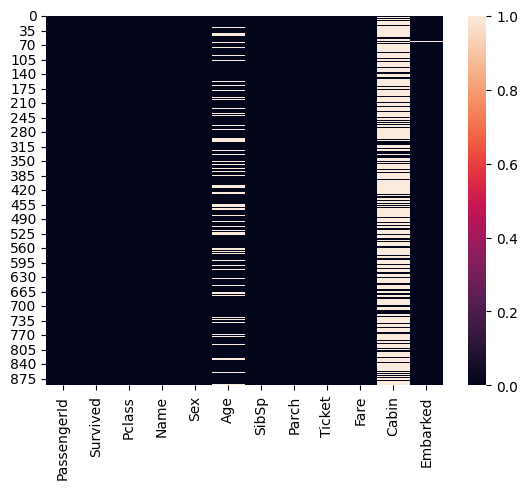

In [100]:
import seaborn as sns
# import matplotlib.pyplot as plt
sns.heatmap(df.isnull())


PREPROCESSING

In [101]:
df = df.drop(columns=["Cabin"])     # DROP HIGHER NULL VALUE COLUMN
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S
...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C


In [102]:
# IMPUTE LOWER NULL VALUE COLUMNS

df["Age"] = df["Age"].fillna(df["Age"].median())       # NULL vaLue Handled by assigning the median

<Axes: >

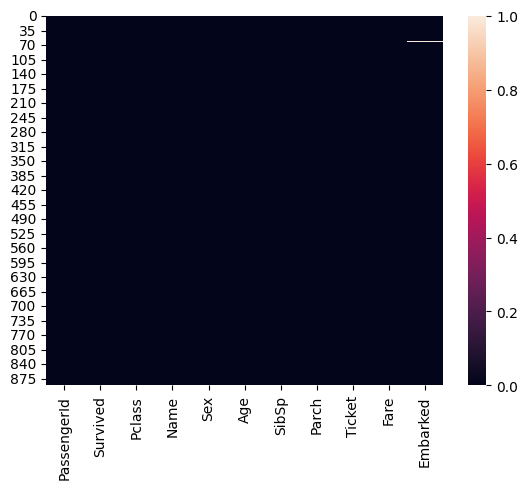

In [103]:
sns.heatmap(df.isnull())

In [104]:
df["Embarked"] = df["Embarked"].fillna(df['Embarked'].mode()[0])

Feature Engineering

In [105]:
# 
      # pandas automatically add the new feature to the df if there is no feature with the name, if there then overwrite  --> if we dont want the feature in our df then take a copy of it  into another df  EX: new_df = df[["Fare"]].copy()
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1   # "SibSp" - No. of siblings / spouses aboard the Titanic, "Parch"- No. of parents / children aboard the Titanic
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,FamilySize
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,2
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,2
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,1
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S,1
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S,1
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,28.0,1,2,W./C. 6607,23.4500,S,4
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C,1


In [106]:
df["IsAlone"] = (df["FamilySize"] == 1)     # by adding .astype(int) show the BOOL dtype as (int)
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,2,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,2,False
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,1,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,2,False
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S,1,True
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S,1,True
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,28.0,1,2,W./C. 6607,23.4500,S,4,False
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C,1,True


In [107]:
df["Title"] = df["Name"].str.extract("([A-Za-z]+)\.")  # Extract the word before . A-Z matches uppercase letters, a-z matches lowercase letters, 
                                                       # () Parentheses create a capturing group. + Means One or more alphabetic letters , \. means Any single character(condition bcz character before . Characters of Uppercase A to Z, Lowercase a to z taken)
df                     
# Regular Expressions (Regex)  
# Behr, Mr. Karl Howell  --> [A-Za-z]+ matches "Behr" because it is made of letters.
# Now It expects a dot (.) immediately after the word. But the next character is: Behr, not (.) so the match fails

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,FamilySize,IsAlone,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,2,False,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,2,False,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,1,True,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,2,False,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,1,True,Mr
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S,1,True,Rev
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S,1,True,Miss
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,28.0,1,2,W./C. 6607,23.4500,S,4,False,Miss
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C,1,True,Mr


In [108]:
# Log Transformation
import numpy as np
df["Log Fare"] = np.log(df["Fare"])
print(df)

# new_df = df[["Fare"],["Log Fare"]]    # index issue


new_df = pd.DataFrame({"Fare":df["Fare"],
                      "Log Fare":df["Log Fare"]})

new_df

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ... 

C:\Users\Arshak\AppData\Roaming\Python\Python313\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Fare,Log Fare
0,7.2500,1.981001
1,71.2833,4.266662
2,7.9250,2.070022
3,53.1000,3.972177
4,8.0500,2.085672
...,...,...
886,13.0000,2.564949
887,30.0000,3.401197
888,23.4500,3.154870
889,30.0000,3.401197


In [109]:
# Encoding
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
print(df["Sex"])

df["Sex"] = encoder.fit_transform(df["Sex"])
df["Sex"]

0        male
1      female
2      female
3      female
4        male
        ...  
886      male
887    female
888    female
889      male
890      male
Name: Sex, Length: 891, dtype: object


0      1
1      0
2      0
3      0
4      1
      ..
886    1
887    0
888    0
889    1
890    1
Name: Sex, Length: 891, dtype: int64

In [110]:

df = df.drop(columns=["PassengerId","Name","Ticket"])
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title,Log Fare
0,0,3,1,22.0,1,0,7.2500,S,2,False,Mr,1.981001
1,1,1,0,38.0,1,0,71.2833,C,2,False,Mrs,4.266662
2,1,3,0,26.0,0,0,7.9250,S,1,True,Miss,2.070022
3,1,1,0,35.0,1,0,53.1000,S,2,False,Mrs,3.972177
4,0,3,1,35.0,0,0,8.0500,S,1,True,Mr,2.085672
...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,1,27.0,0,0,13.0000,S,1,True,Rev,2.564949
887,1,1,0,19.0,0,0,30.0000,S,1,True,Miss,3.401197
888,0,3,0,28.0,1,2,23.4500,S,4,False,Miss,3.154870
889,1,1,1,26.0,0,0,30.0000,C,1,True,Mr,3.401197


Scaling

In [120]:
from sklearn.preprocessing import RobustScaler

x = df.drop(columns=["Survived"])     # so  by removing Survived all other will store
y = df["Survived"]

print(x)


scale_cols = ["Age","Fare","SibSp","Parch","FamilySize"]

scaler = RobustScaler()

print(x[scale_cols])
x[scale_cols] = scaler.fit_transform(x[scale_cols])
x[scale_cols]


     Pclass  Sex   Age  SibSp  Parch     Fare Embarked  FamilySize  IsAlone  \
0         3    1  22.0      1      0   7.2500        S           2    False   
1         1    0  38.0      1      0  71.2833        C           2    False   
2         3    0  26.0      0      0   7.9250        S           1     True   
3         1    0  35.0      1      0  53.1000        S           2    False   
4         3    1  35.0      0      0   8.0500        S           1     True   
..      ...  ...   ...    ...    ...      ...      ...         ...      ...   
886       2    1  27.0      0      0  13.0000        S           1     True   
887       1    0  19.0      0      0  30.0000        S           1     True   
888       3    0  28.0      1      2  23.4500        S           4    False   
889       1    1  26.0      0      0  30.0000        C           1     True   
890       3    1  32.0      0      0   7.7500        Q           1     True   

    Title  Log Fare  
0      Mr  1.981001  
1     M

,Age,Fare,SibSp,Parch,FamilySize
0,-0.461538,-0.312011,1.0,0.0,1.0
1,0.769231,2.461242,1.0,0.0,1.0
2,-0.153846,-0.282777,0.0,0.0,0.0
3,0.538462,1.673732,1.0,0.0,1.0
4,0.538462,-0.277363,0.0,0.0,0.0
...,...,...,...,...,...
886,-0.076923,-0.062981,0.0,0.0,0.0
887,-0.692308,0.673281,0.0,0.0,0.0
888,0.000000,0.389604,1.0,2.0,3.0
889,-0.153846,0.673281,0.0,0.0,0.0


In [125]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE

model = LogisticRegression()

rfe = RFE(model, n_features_to_select=2)
rfe.fit_transform(x,y)

ValueError: could not convert string to float: 'S'